# Prediksi Banjir di Indonesia

**Proyek klasifikasi machine learning ? target: `flood` (0 = tidak banjir, 1 = banjir).**

Notebook ini mencakup audit data, eksplorasi, rekayasa fitur musiman, pemisahan data berdasarkan waktu, perbandingan model dengan validasi silang time-series, tuning hyperparameter, dan evaluasi final.

> **Batasan penggunaan:** hasil ini merupakan eksperimen pembelajaran pada dataset yang tersedia, bukan sistem peringatan dini siap operasional. Sumber, cakupan lokasi, definisi waktu prediksi, dan kualitas label perlu diverifikasi sebelum penggunaan nyata.

## 1. Konfigurasi dan impor

Jalankan notebook dari direktori project agar file CSV dapat ditemukan. Seluruh preprocessing yang belajar dari data (imputasi dan scaling) berada dalam pipeline dan di-fit hanya pada bagian training di setiap fold.

In [2]:
from pathlib import Path
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyClassifier
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    average_precision_score,
    balanced_accuracy_score,
    classification_report,
    confusion_matrix,
    f1_score,
    make_scorer,
    precision_recall_curve,
    precision_score,
    recall_score,
    roc_auc_score,
    roc_curve,
)
from sklearn.model_selection import GridSearchCV, TimeSeriesSplit
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier

RANDOM_STATE = 42
TEST_MONTH_FRACTION = 0.20
N_SPLITS = 5
DATA_PATH = Path(r"C:\Users\jabes\OneDrive\Documents\Dataset\flood_prediction_indonesia.csv")

sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (10, 5)
pd.set_option("display.max_columns", 30)


## 2. Memuat dan memvalidasi data

Validasi di sini memastikan kolom wajib, nilai target, dan bulan tersedia. Duplikat dan data hilang dilaporkan; nilai hilang ditangani oleh imputasi di pipeline, sedangkan baris duplikat tidak dihapus otomatis karena pengulangan waktu/lokasi bisa bermakna.

In [3]:
if not DATA_PATH.is_file():
    raise FileNotFoundError(
        f"File data tidak ditemukan: {DATA_PATH.resolve()}. "
        "Jalankan notebook dari direktori project atau ubah DATA_PATH."
    )

df = pd.read_csv(DATA_PATH) 
required_columns = {
    "rainfall_mm", "rainfall_3day_mm", "river_level_m", "humidity",
    "temperature", "wind_speed", "elevation", "dist_river_km",
    "drainage_index", "pop_density", "latitude", "longitude",
    "Year", "Month", "flood",
}
missing_columns = required_columns.difference(df.columns)
if missing_columns:
    raise ValueError(f"Kolom wajib tidak ditemukan: {sorted(missing_columns)}")

if df["flood"].isna().any():
    raise ValueError("Kolom target 'flood' memiliki nilai kosong.")
if not set(df["flood"].unique()).issubset({0, 1}):
    raise ValueError("Target 'flood' harus berisi label biner 0 dan 1.")
if not df["Month"].between(1, 12).all():
    raise ValueError("Kolom 'Month' harus berisi angka 1 sampai 12.")

print(f"Ukuran data: \n - {df.shape[0]:,} baris \n - {df.shape[1]} kolom")
display(df.head())

Ukuran data: 
 - 800 baris 
 - 15 kolom


,rainfall_mm,rainfall_3day_mm,river_level_m,humidity,temperature,wind_speed,elevation,dist_river_km,drainage_index,pop_density,latitude,longitude,Year,Month,flood
0,107.4,251.1,3.85,89,29.6,13.4,21.9,0.46,7,4177,0.9831,124.8238,2024,12,1
1,44.0,109.0,3.07,79,31.1,14.6,23.2,2.40,6,2216,1.9677,124.9946,2024,12,0
2,72.5,103.2,2.98,74,28.2,5.3,36.6,1.94,6,18093,3.6575,98.5927,2024,12,1
3,46.6,141.9,3.04,80,27.1,10.3,23.7,1.92,2,22463,3.8686,98.6404,2024,12,0
4,113.8,192.2,4.91,89,29.8,12.5,148.6,2.39,3,6157,-6.9895,107.1741,2024,12,1


## 3. Audit kualitas data

In [4]:
audit = pd.DataFrame({
    "dtype": df.dtypes.astype(str),
    "missing": df.isna().sum(),
    "missing_%": (df.isna().mean() * 100).round(2),
    "unique": df.nunique(dropna=False), 
})
display(audit)
print(f"Baris duplicated: {df.duplicated().sum():,}")
print("\nDistribusi target:")
display(
    df["flood"].value_counts(dropna=False)
      .rename_axis("flood")
      .to_frame("jumlah")
      .assign(persen=lambda x: (x["jumlah"] / len(df) * 100).round(2))
)
print(f"Rentang tahun: {df['Year'].min()}-{df['Year'].max()}")
print(f"Jumlah periode Year-Month unik: {df[['Year', 'Month']].drop_duplicates().shape[0]}")

,dtype,missing,missing_%,unique
rainfall_mm,float64,0,0.0,567
rainfall_3day_mm,float64,0,0.0,677
river_level_m,float64,0,0.0,428
humidity,int64,0,0.0,43
temperature,float64,0,0.0,98
wind_speed,float64,0,0.0,250
elevation,float64,0,0.0,417
dist_river_km,float64,0,0.0,367
drainage_index,int64,0,0.0,10
pop_density,int64,0,0.0,760


Baris duplicated: 0

Distribusi target:


,jumlah,persen
flood,,
0,510,63.75
1,290,36.25


Rentang tahun: 2010-2024
Jumlah periode Year-Month unik: 174


## 4. Eksplorasi target dan variabel

Visualisasi ini membantu memahami distribusi kelas, tren data historis, skala fitur, dan kemungkinan nilai ekstrem. Nilai ekstrem tidak dipotong otomatis: tanpa konteks domain, clipping dapat menghapus sinyal banjir yang valid.

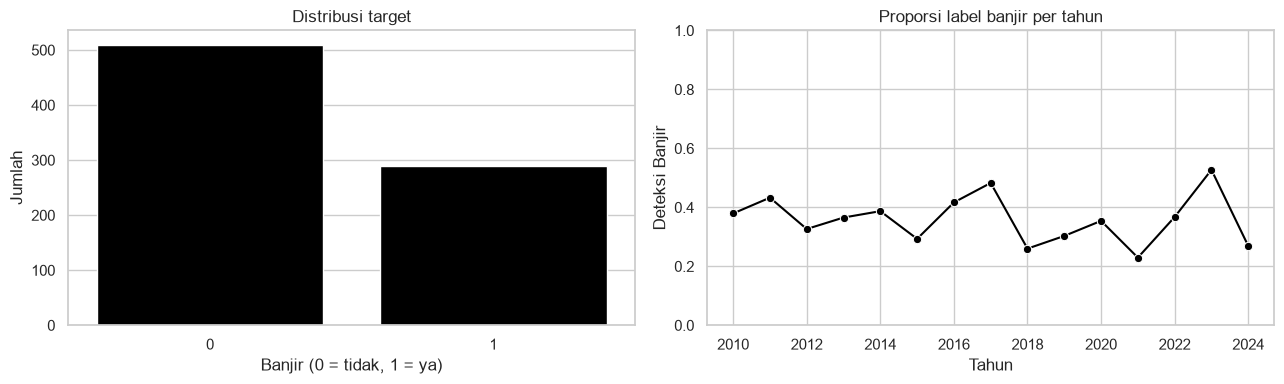

,count,mean,std,min,25%,50%,75%,max
rainfall_mm,800.0,51.49,46.68,0.30,18.40,37.55,70.70,386.70
rainfall_3day_mm,800.0,125.88,82.81,14.90,64.35,106.00,167.98,634.00
river_level_m,800.0,3.48,1.64,0.30,2.32,3.22,4.39,12.00
humidity,800.0,76.88,8.29,55.00,71.00,76.00,82.00,100.00
temperature,800.0,29.66,1.85,22.80,28.50,29.70,30.90,36.00
wind_speed,800.0,13.29,7.08,2.00,8.10,12.10,17.00,48.90
elevation,800.0,90.38,294.64,1.00,7.60,15.80,31.70,2000.00
dist_river_km,800.0,1.91,1.57,0.05,0.82,1.51,2.48,9.87
drainage_index,800.0,5.34,2.01,1.00,4.00,5.00,7.00,10.00
pop_density,800.0,5117.91,4880.24,339.00,1955.25,3557.00,6558.25,30000.00


In [16]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
sns.countplot(data=df, x="flood", ax=axes[0], color="black")
axes[0].set(title="Distribusi target", xlabel="Banjir (0 = tidak, 1 = ya)", ylabel="Jumlah")

flood_by_year = df.groupby("Year", as_index=False)["flood"].mean()
sns.lineplot(data=flood_by_year, x="Year", y="flood", color='black',marker="o", ax=axes[1])
axes[1].set(title="Proporsi label banjir per tahun", xlabel='Tahun', ylabel='Deteksi Banjir')
axes[1].set_ylim(0, 1)
plt.tight_layout()
plt.show()

display(df.drop(columns="flood").describe().T.round(2))

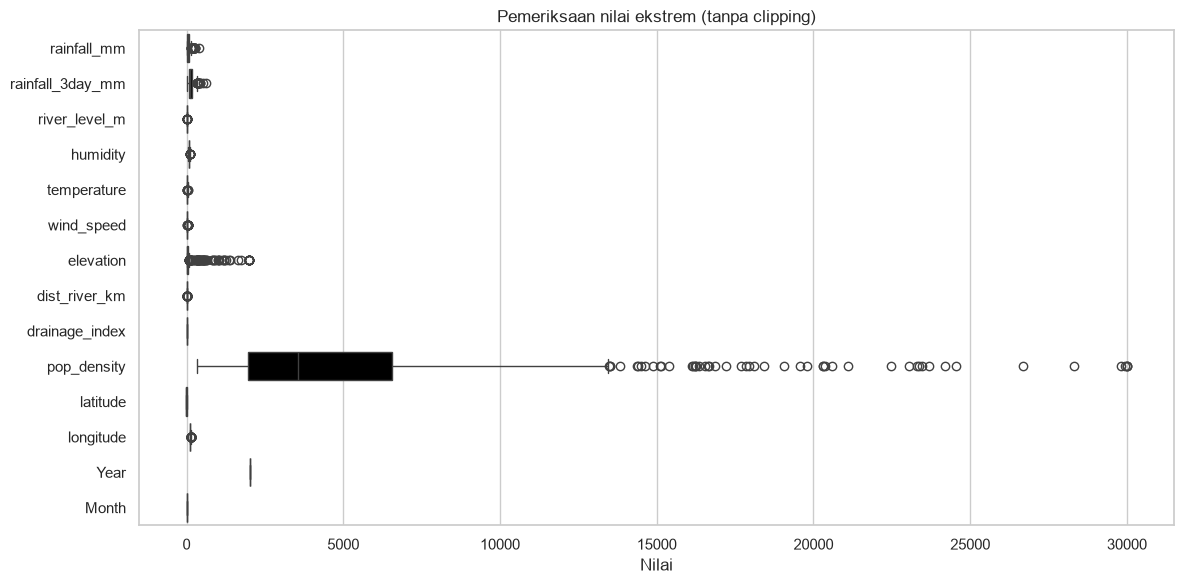

In [17]:
numeric_for_plot = df.drop(columns=['flood']).columns
fig, ax = plt.subplots(figsize=(12, 6))
sns.boxplot(data=df[numeric_for_plot], orient="h", ax=ax , color='black')
ax.set(title="Pemeriksaan nilai ekstrem (tanpa clipping)", xlabel="Nilai")
plt.tight_layout()
plt.show()

## 5. Rekayasa fitur dan pemisahan berdasarkan waktu

Data diurutkan menurut `Year-Month`; 20% periode terbaru menjadi test set yang tidak digunakan untuk memilih model atau hyperparameter. Semua baris pada bulan yang sama tetap berada pada sisi split yang sama. `Month` diubah menjadi fitur siklik agar Desember dan Januari berdekatan secara matematis. `Year` tetap dipertahankan sebagai fitur tren.

Untuk deployment prediksi masa depan, definisi waktu fitur dan target harus dipastikan: fitur harus tersedia sebelum kejadian yang diprediksi.

In [7]:
data = df.sort_values(["Year", "Month"], kind="stable").reset_index(drop=True).copy()
data["month_sin"] = np.sin(2 * np.pi * data["Month"] / 12)
data["month_cos"] = np.cos(2 * np.pi * data["Month"] / 12)

unique_periods = (
    data[["Year", "Month"]]
    .drop_duplicates()
    .reset_index(drop=True)
)
split_period_index = int(np.floor(len(unique_periods) * (1 - TEST_MONTH_FRACTION)))
if split_period_index <= 0 or split_period_index >= len(unique_periods):
    raise ValueError("Jumlah periode tidak cukup untuk membuat split train/test.")

test_start = unique_periods.iloc[split_period_index]
period_id = data["Year"] * 12 + data["Month"]
test_start_id = int(test_start["Year"] * 12 + test_start["Month"])
train_mask = period_id < test_start_id
test_mask = ~train_mask

TARGET = "flood"
FEATURES_TO_DROP = [TARGET, "Month"]
X = data.drop(columns=FEATURES_TO_DROP)
y = data[TARGET].astype(int)
X_train = X.loc[train_mask].reset_index(drop=True)
X_test = X.loc[test_mask].reset_index(drop=True)
y_train = y.loc[train_mask].reset_index(drop=True)
y_test = y.loc[test_mask].reset_index(drop=True)
train_period_id = period_id.loc[train_mask].reset_index(drop=True)
test_period_id = period_id.loc[test_mask].reset_index(drop=True)

if y_train.nunique() != 2 or y_test.nunique() != 2:
    raise ValueError("Train dan test harus masing-masing memuat kedua kelas target.")
if set(train_period_id).intersection(set(test_period_id)):
    raise AssertionError("Periode yang sama ditemukan di train dan test.")

print(f"Periode awal test: {int(test_start['Year'])}-{int(test_start['Month']):02d}")
print(f"Data Train: {X_train.shape[0]} baris\nData Test: {X_test.shape[0]} baris")
print(f"Distribusi train: {y_train.value_counts(normalize=True).sort_index().round(3).to_dict()}")
print(f"Distribusi test:  {y_test.value_counts(normalize=True).sort_index().round(3).to_dict()}")

Periode awal test: 2021-12
Data Train: 639 baris
Data Test: 161 baris
Distribusi train: {0: 0.645, 1: 0.355}
Distribusi test:  {0: 0.609, 1: 0.391}


## 6. Pipeline dan validasi silang berurutan

Imputasi median dan standardisasi berada di dalam `Pipeline`, sehingga setiap fold hanya belajar preprocessing dari bagian training fold. Validasi memakai expanding-window `TimeSeriesSplit` atas periode bulanan unik; satu bulan tidak akan terbagi antara train dan validasi. Test set tetap disimpan untuk evaluasi final saja.

In [ ]:
numeric_features = X_train.columns.tolist()
preprocessor = ColumnTransformer(
    transformers=[
        (
            "numeric",
            Pipeline([
                ("imputer", SimpleImputer(strategy="median")),
                ("scaler", StandardScaler()),
            ]),
            numeric_features,
        )
    ],
    remainder="drop",
)
train_periods = pd.Series(train_period_id.unique()).sort_values().reset_index(drop=True)
period_cv = TimeSeriesSplit(n_splits=N_SPLITS)
cv_splits = []
for train_period_idx, valid_period_idx in period_cv.split(train_periods):
    fold_train_periods = train_periods.iloc[train_period_idx]
    fold_valid_periods = train_periods.iloc[valid_period_idx]
    fold_train_idx = np.flatnonzero(train_period_id.isin(fold_train_periods).to_numpy())
    fold_valid_idx = np.flatnonzero(train_period_id.isin(fold_valid_periods).to_numpy())
    cv_splits.append((fold_train_idx, fold_valid_idx))

print(f"Fold validasi: {len(cv_splits)}")
for fold_number, (train_idx, valid_idx) in enumerate(cv_splits, start=1):
    fold_train_months = train_period_id.iloc[train_idx].nunique()
    fold_valid_months = train_period_id.iloc[valid_idx].nunique()
    print(
        f"Fold {fold_number}: {len(train_idx)} train rows / {fold_train_months} bulan; "
        f"{len(valid_idx)} validasi rows / {fold_valid_months} bulan"
    )

Fold validasi: 5
Fold 1: 129 train rows / 24 bulan; 97 validasi rows / 23 bulan
Fold 2: 226 train rows / 47 bulan; 112 validasi rows / 23 bulan
Fold 3: 338 train rows / 70 bulan; 114 validasi rows / 23 bulan
Fold 4: 452 train rows / 93 bulan; 82 validasi rows / 23 bulan
Fold 5: 534 train rows / 116 bulan; 105 validasi rows / 23 bulan


## 7. Perbandingan model dan tuning hyperparameter

Semua kandidat dinilai pada fold historis yang sama dengan F1 sebagai metrik pemilihan. Dummy prior menjadi baseline; model terpilih ditentukan dari rata-rata F1 validasi silang, bukan dari skor test. Precision, recall, dan ROC-AUC validasi ikut dicatat untuk konteks.

In [9]:
model_grids = {
    "Baseline (prior)": (
        DummyClassifier(strategy="prior"),
        [{}],
    ),
    "Logistic Regression": (
        LogisticRegression(max_iter=2000, random_state=RANDOM_STATE),
        {
            "classifier__C": [0.01, 0.1, 1.0, 10.0],
            "classifier__class_weight": [None, "balanced"],
        },
    ),
    "K-Nearest Neighbors": (
        KNeighborsClassifier(),
        {
            "classifier__n_neighbors": [5, 11, 21],
            "classifier__weights": ["uniform", "distance"],
        },
    ),
    "Support Vector Machine": (
        SVC(random_state=RANDOM_STATE),
        {
            "classifier__C": [0.1, 1.0, 10.0],
            "classifier__gamma": ["scale", "auto"],
            "classifier__class_weight": [None, "balanced"],
        },
    ),
    "Decision Tree": (
        DecisionTreeClassifier(random_state=RANDOM_STATE),
        {
            "classifier__max_depth": [None, 5, 10],
            "classifier__min_samples_leaf": [2, 5],
            "classifier__class_weight": [None, "balanced"],
        },
    ),
    "Random Forest": (
        RandomForestClassifier(random_state=RANDOM_STATE, n_jobs=1),
        {
            "classifier__n_estimators": [150],
            "classifier__max_depth": [None, 10],
            "classifier__min_samples_leaf": [2, 5],
            "classifier__class_weight": [None, "balanced"],
        },
    ),
}

scoring = {
    "f1": make_scorer(f1_score, zero_division=0),
    "precision": make_scorer(precision_score, zero_division=0),
    "recall": make_scorer(recall_score, zero_division=0),
    "roc_auc": "roc_auc",
}

searches = {}
cv_rows = []

for model_name, (estimator, parameter_grid) in model_grids.items():
    pipeline = Pipeline([
        ("preprocessor", preprocessor),
        ("classifier", estimator),
    ])
    search = GridSearchCV(
        estimator=pipeline,
        param_grid=parameter_grid,
        scoring=scoring,
        refit="f1",
        cv=cv_splits,
        n_jobs=1,
        error_score="raise",
        return_train_score=False,
    )
    search.fit(X_train, y_train)
    searches[model_name] = search
    best_index = search.best_index_
    cv_rows.append({
        "Model": model_name,
        "CV F1 mean": search.cv_results_["mean_test_f1"][best_index],
        "CV F1 std": search.cv_results_["std_test_f1"][best_index],
        "CV precision": search.cv_results_["mean_test_precision"][best_index],
        "CV recall": search.cv_results_["mean_test_recall"][best_index],
        "CV ROC-AUC": search.cv_results_["mean_test_roc_auc"][best_index],
        "Best params": search.best_params_,
    })

cv_results = (
    pd.DataFrame(cv_rows)
    .sort_values("CV F1 mean", ascending=False)
    .reset_index(drop=True)
)
display(cv_results.round(1).sort_values(by='CV F1 mean', ascending=False))

,Model,CV F1 mean,CV F1 std,CV precision,CV recall,CV ROC-AUC,Best params
0,Logistic Regression,0.7,0.0,0.7,0.8,0.8,"{'classifier__C': 0.1, 'classifier__class_weig..."
1,Random Forest,0.7,0.1,0.7,0.7,0.8,"{'classifier__class_weight': 'balanced', 'clas..."
2,Support Vector Machine,0.6,0.1,0.6,0.7,0.8,"{'classifier__C': 0.1, 'classifier__class_weig..."
3,Decision Tree,0.6,0.1,0.6,0.6,0.7,"{'classifier__class_weight': 'balanced', 'clas..."
4,K-Nearest Neighbors,0.6,0.1,0.7,0.5,0.8,"{'classifier__n_neighbors': 11, 'classifier__w..."
5,Baseline (prior),0.0,0.0,0.0,0.0,0.5,{}


## 8. Pemilihan model dan evaluasi final

Model dengan F1 validasi silang terbaik dipilih tanpa melihat test. Sesudah itu, test set historis terbaru dievaluasi satu kali pada threshold default 0,5. Untuk penggunaan operasional, threshold sebaiknya ditetapkan berdasarkan biaya false negative/false positive dan hanya menggunakan data validasi, bukan test.

In [10]:
best_model_name = cv_results.loc[0, "Model"]
final_search = searches[best_model_name]
final_model = final_search.best_estimator_

y_pred = final_model.predict(X_test)
if hasattr(final_model, "predict_proba"):
    y_score = final_model.predict_proba(X_test)[:, 1]
else:
    y_score = final_model.decision_function(X_test)

test_metrics = pd.Series({
    "Model terpilih": best_model_name,
    "Accuracy": accuracy_score(y_test, y_pred),
    "Balanced accuracy": balanced_accuracy_score(y_test, y_pred),
    "Precision (banjir)": precision_score(y_test, y_pred, zero_division=0),
    "Recall (banjir)": recall_score(y_test, y_pred, zero_division=0),
    "F1 (banjir)": f1_score(y_test, y_pred, zero_division=0),
    "ROC-AUC": roc_auc_score(y_test, y_score),
    "Average precision": average_precision_score(y_test, y_score),
})
display(test_metrics.to_frame("Nilai"))
baseline_cv_f1 = cv_results.loc[
    cv_results["Model"] == "Baseline (prior)", "CV F1 mean"
].iloc[0]
false_negatives = int(((y_test == 1) & (y_pred == 0)).sum())
print(f"Model terpilih: {best_model_name}")
print(f"F1 CV model terpilih: {final_search.best_score_:.3f}")
print(f"F1 CV baseline prior: {baseline_cv_f1:.3f}")
print(f"False negative pada test (banjir diprediksi tidak banjir): {false_negatives}")
print("\nClassification report (test):")
print(classification_report(y_test, y_pred, target_names=["Tidak banjir", "Banjir"], zero_division=0))

,Nilai
Model terpilih,Logistic Regression
Accuracy,0.770186
Balanced accuracy,0.765873
Precision (banjir),0.691176
Recall (banjir),0.746032
F1 (banjir),0.717557
ROC-AUC,0.833171
Average precision,0.781406


Model terpilih: Logistic Regression
F1 CV model terpilih: 0.703
F1 CV baseline prior: 0.000
False negative pada test (banjir diprediksi tidak banjir): 16

Classification report (test):
              precision    recall  f1-score   support

Tidak banjir       0.83      0.79      0.81        98
      Banjir       0.69      0.75      0.72        63

    accuracy                           0.77       161
   macro avg       0.76      0.77      0.76       161
weighted avg       0.77      0.77      0.77       161



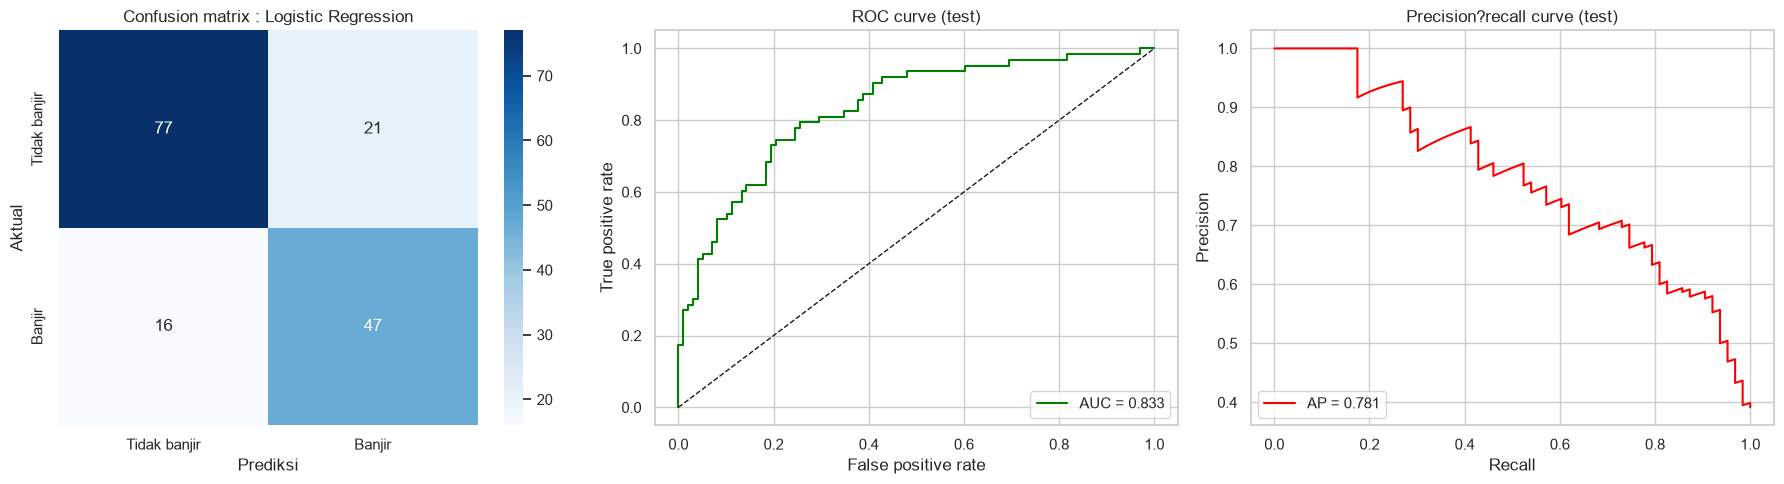

In [11]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

cm = confusion_matrix(y_test, y_pred, labels=[0, 1])
sns.heatmap(
    cm, annot=True, fmt="d", cmap="Blues", cbar=True,
    xticklabels=["Tidak banjir", "Banjir"],
    yticklabels=["Tidak banjir", "Banjir"],
    ax=axes[0],
)
axes[0].set(title=f"Confusion matrix : {best_model_name}", xlabel="Prediksi", ylabel="Aktual")

fpr, tpr, _ = roc_curve(y_test, y_score)
axes[1].plot(fpr, tpr, color='Green' , label=f"AUC = {roc_auc_score(y_test, y_score):.3f}")
axes[1].plot([0, 1], [0, 1], "k--", linewidth=1)
axes[1].set(title="ROC curve (test)", xlabel="False positive rate", ylabel="True positive rate")
axes[1].legend(loc="lower right")

precision_curve, recall_curve, _ = precision_recall_curve(y_test, y_score)
axes[2].plot(recall_curve, precision_curve, color='red' ,label=f"AP = {average_precision_score(y_test, y_score):.3f}",)
axes[2].set(title="Precision?recall curve (test)", xlabel="Recall", ylabel="Precision",)
axes[2].legend(loc="lower left")

plt.tight_layout()
plt.show()

## 9. Kesimpulan dan batasan

Isi kesimpulan berdasarkan hasil yang tampil setelah notebook dijalankan dari atas:

- Catat model terpilih, skor validasi silang, serta metrik test?terutama recall banjir dan jumlah false negative.
- Bandingkan dengan baseline prior; jika kinerja model tidak lebih baik secara bermakna, jangan klaim model memberi nilai tambah.
- Test set ini hanya merepresentasikan periode historis yang disisihkan. Ukuran data (800 baris) dan jumlah periode terbatas, sehingga ketidakpastian skor masih tinggi.
- Pastikan sumber data, wilayah, cara label banjir dibuat, dan kapan setiap fitur tersedia. Periksa potensi duplikasi lokasi/periode dan kebocoran informasi target sebelum deployment.
- Sebelum penggunaan nyata, lakukan validasi geografis/temporal yang sesuai, kalibrasi probabilitas, analisis biaya kesalahan, pemantauan drift, serta tinjauan ahli kebencanaan.

### Reproduksibilitas

Gunakan `requirements.txt` di direktori project, jalankan notebook secara berurutan, dan simpan perubahan data/configuration bersama hasil eksperimen. Seed acak dikunci untuk estimator yang mendukungnya.